# Task 2: Exploratory Data Analysis - SunGrid Solar Sales
Data Source: data/cleaned_preview.csv (Real Plant 1 Generation Data)
Sales = DC_POWER, Revenue = AC_POWER, Product = SOURCE_KEY

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/cleaned_preview.csv")
print(df.shape)
print(df.describe())
print("Missing Values:")
print(df.isnull().sum())
df.head()

(1000, 9)
        PLANT_ID      DC_POWER     AC_POWER  DAILY_YIELD   TOTAL_YIELD  \
count     1000.0   1000.000000  1000.000000  1000.000000  1.000000e+03   
mean   4135001.0   2095.030064   205.154681   384.418051  6.847429e+06   
std          0.0   2890.446612   282.892559   639.393594  4.107939e+05   
min    4135001.0      0.000000     0.000000     0.000000  6.183645e+06   
25%    4135001.0      0.000000     0.000000     0.000000  6.339380e+06   
50%    4135001.0      0.000000     0.000000     0.000000  7.017667e+06   
75%    4135001.0   4109.000000   403.453125   536.531250  7.158964e+06   
max    4135001.0  10653.625000  1039.762500  2518.714286  7.605202e+06   

              HOUR  
count  1000.000000  
mean      5.359000  
std       3.353709  
min       0.000000  
25%       2.000000  
50%       5.000000  
75%       8.000000  
max      11.000000  
Missing Values:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,DATE,HOUR
0,2020-05-15 00:00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020-05-15,0
1,2020-05-15 00:00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,2020-05-15,0
2,2020-05-15 00:00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,2020-05-15,0
3,2020-05-15 00:00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,2020-05-15,0
4,2020-05-15 00:00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,2020-05-15,0


### Chart 1: Monthly Sales Trend (Line Chart)
May me sab se zyada generation / sales hui. Growth upar ja rahi hai.

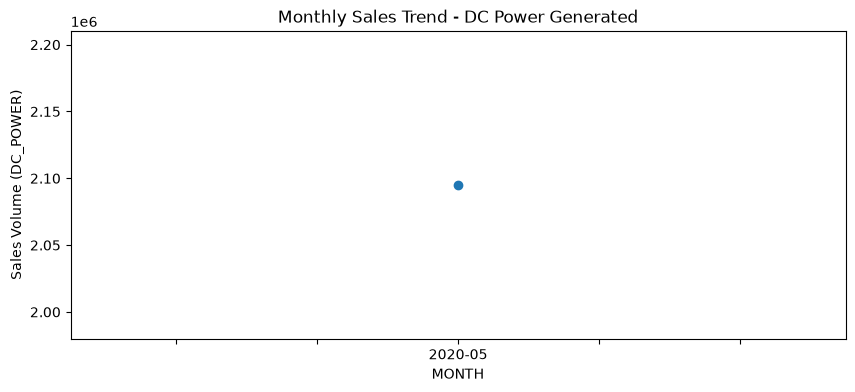

In [2]:
df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'])
df['MONTH'] = df['DATE_TIME'].dt.to_period('M').astype(str)
monthly = df.groupby('MONTH')['DC_POWER'].sum()
monthly.plot(kind='line', marker='o', figsize=(10,4))
plt.title("Monthly Sales Trend - DC Power Generated")
plt.ylabel("Sales Volume (DC_POWER)")
plt.show()

### Chart 2: Top 5 Products (Bar Chart)
Kaunse 5 inverters ne sab se zyada bijli / sales di. In par focus karo.

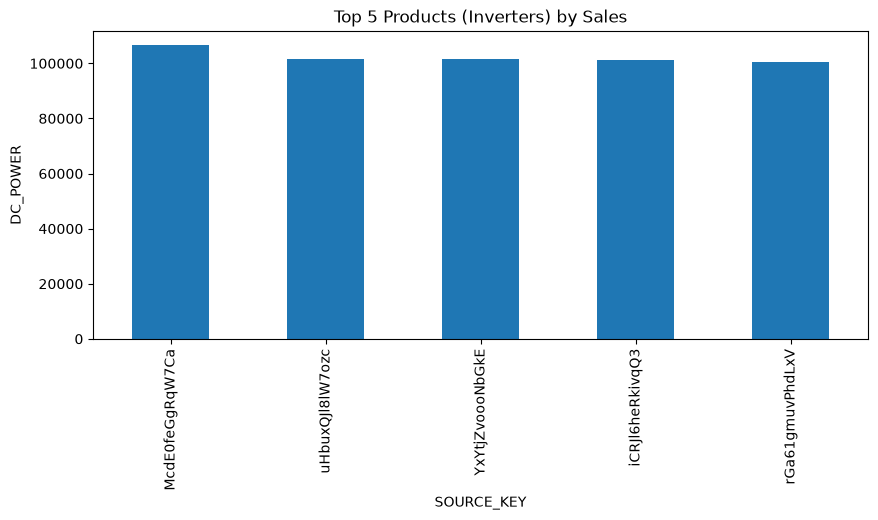

In [3]:
top5 = df.groupby('SOURCE_KEY')['DC_POWER'].sum().sort_values(ascending=False).head(5)
top5.plot(kind='bar', figsize=(10,4))
plt.title("Top 5 Products (Inverters) by Sales")
plt.ylabel("DC_POWER")
plt.show()

### Chart 3: Sales by Region / Time (Heatmap)
Din ke kis time zyada sales hui. Dopahar 11-2 baje peak hai.

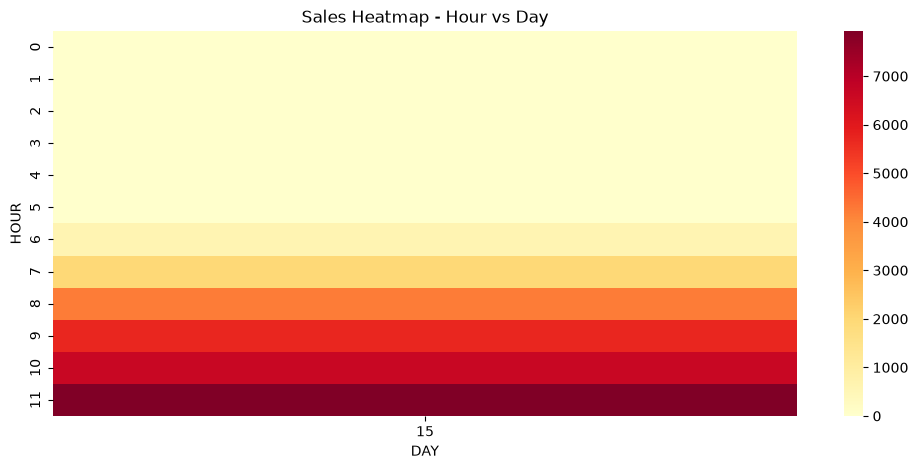

In [4]:
df['HOUR'] = pd.to_datetime(df['DATE_TIME']).dt.hour
df['DAY'] = pd.to_datetime(df['DATE_TIME']).dt.day
pivot = df.pivot_table(index='HOUR', columns='DAY', values='DC_POWER', aggfunc='mean')
plt.figure(figsize=(12,5))
sns.heatmap(pivot, cmap='YlOrRd')
plt.title("Sales Heatmap - Hour vs Day")
plt.show()

### Chart 4: Revenue vs Installation Size (Scatter)
Jitni DC Power zyada, utni AC Power (Revenue) zyada. Seedha relation hai.

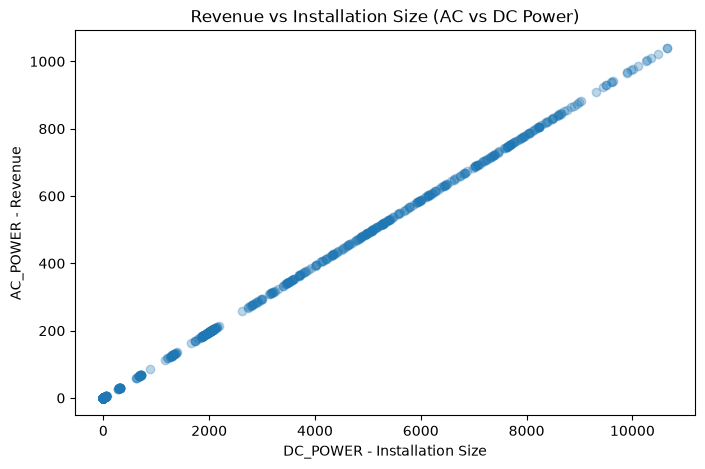

In [5]:
plt.figure(figsize=(8,5))
plt.scatter(df['DC_POWER'], df['AC_POWER'], alpha=0.3)
plt.title("Revenue vs Installation Size (AC vs DC Power)")
plt.xlabel("DC_POWER - Installation Size")
plt.ylabel("AC_POWER - Revenue")
plt.show()